# Ruteo de vehículos con ventanas de tiempo (VRPTW): reparto a farmacias

Un centro de distribución abastece a 8 farmacias con una flota de 3 camiones de capacidad limitada. Cada farmacia
solo puede recibir dentro de un horario (ventana de tiempo). ¿Qué ruta hace cada camión para **minimizar la
distancia total** cumpliendo capacidad y horarios?

1. **Parte A – Ejercicio del ramo.** Se replica la ayudantía de Investigación de Operaciones (originalmente en
   Gurobi) y se verifica el óptimo de la pauta (290).
2. **Parte B – Modelo corregido.** La formulación de la pauta no controla el tiempo de salida desde el depósito;
   se agrega esa restricción y se ve cómo cambian las rutas.
3. **Parte C – Caso Coquimbo–La Serena.** El mismo modelo con puntos reales de la conurbación, distancias por
   carretera aproximadas y un mapa interactivo.

Se usa **PuLP + CBC** (gratis, sin licencia). La pauta original usaba Gurobi; aquí se usa un solver libre para que corra en cualquier parte.

In [1]:
import math, itertools, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pulp
from pathlib import Path

FIG = Path("../figures"); FIG.mkdir(exist_ok=True)
SOLVER = pulp.PULP_CBC_CMD(msg=False, timeLimit=300)

## Formulación

Conjuntos: nodos $N = \{0,\dots,n\}$ (0 = depósito), clientes $C = N \setminus \{0\}$, vehículos $K$.

Variables: $x_{ijk} \in \{0,1\}$ si el vehículo $k$ va de $i$ a $j$; $T_{ik} \ge 0$ hora de llegada de $k$ a $i$.

$$\min \sum_{k}\sum_{i \ne j} c_{ij}\,x_{ijk}$$

sujeto a:
1. Cada cliente se visita exactamente una vez: $\sum_k\sum_{j} x_{ijk} = 1 \;\; \forall i \in C$
2. Cada vehículo sale y vuelve al depósito una vez: $\sum_{j \in C} x_{0jk} = \sum_{i \in C} x_{i0k} = 1$
3. Conservación de flujo: $\sum_j x_{hjk} = \sum_i x_{ihk} \;\; \forall h \in C, k$
4. Capacidad: $\sum_{i \in C} q_i \sum_j x_{ijk} \le Q$
5. Tiempos (elimina subtours): $T_{ik} + t_{ij} - M(1-x_{ijk}) \le T_{jk}$
6. Ventanas: $l_i \le T_{ik} \le u_i$

In [2]:
def solve_vrptw(coords, demand, windows, Q, n_veh, dist=None, ttime=None, depot_times=False, M=10_000):
    """Resuelve el VRPTW. depot_times=False replica la pauta (restricción 5 solo entre clientes)."""
    nodes = list(range(len(coords))); clients = nodes[1:]; K = list(range(1, n_veh + 1))
    if dist is None:
        dist = {(i, j): math.dist(coords[i], coords[j]) for i in nodes for j in nodes if i != j}
    if ttime is None:
        ttime = dist
    arcs = [(i, j) for i in nodes for j in nodes if i != j]
    m = pulp.LpProblem("VRPTW", pulp.LpMinimize)
    x = pulp.LpVariable.dicts("x", [(i, j, k) for i, j in arcs for k in K], cat="Binary")
    T = {(k, i): pulp.LpVariable(f"T_{k}_{i}", lowBound=windows[i][0], upBound=windows[i][1]) for k in K for i in nodes}
    m += pulp.lpSum(dist[i, j] * x[i, j, k] for i, j in arcs for k in K)
    for i in clients:
        m += pulp.lpSum(x[i, j, k] for j in nodes if j != i for k in K) == 1
        m += pulp.lpSum(x[j, i, k] for j in nodes if j != i for k in K) == 1
    for k in K:
        m += pulp.lpSum(x[0, j, k] for j in clients) == 1
        m += pulp.lpSum(x[i, 0, k] for i in clients) == 1
        m += pulp.lpSum(demand[i] * x[i, j, k] for i in clients for j in nodes if j != i) <= Q
        for h in clients:
            m += pulp.lpSum(x[h, j, k] for j in nodes if j != h) == pulp.lpSum(x[i, h, k] for i in nodes if i != h)
        for i in clients:
            for j in clients:
                if i != j:
                    m += T[k, i] + ttime[i, j] - M * (1 - x[i, j, k]) <= T[k, j]
        if depot_times:
            m += T[k, 0] == windows[0][0]
            for j in clients:
                m += T[k, 0] + ttime[0, j] - M * (1 - x[0, j, k]) <= T[k, j]
    t0 = time.time(); m.solve(SOLVER)
    routes = {}
    for k in K:
        route, cur = [0], 0
        while True:
            nxt = [j for j in nodes if j != cur and pulp.value(x[cur, j, k]) > 0.5]
            if not nxt: break
            cur = nxt[0]; route.append(cur)
            if cur == 0: break
        routes[k] = route
    arrival = {(k, i): pulp.value(T[k, i]) for k in K for i in routes[k]}
    return {"status": pulp.LpStatus[m.status], "obj": pulp.value(m.objective), "routes": routes,
            "arrival": arrival, "secs": time.time() - t0, "dist": dist}

## Parte A – Ejercicio de la ayudantía

In [3]:
windows = [(0, 300), (30, 90), (20, 80), (50, 120), (60, 140), (25, 60), (10, 50), (40, 100), (55, 150)]
q = [0, 10, 20, 15, 8, 12, 5, 10, 7]
coords = [(60, 60), (20, 50), (25, 30), (45, 80), (70, 90), (50, 40), (30, 20), (65, 30), (80, 70)]
Q, N_VEH = 40, 3
pd.DataFrame({"x": [c[0] for c in coords], "y": [c[1] for c in coords], "demanda": q,
              "abre": [w[0] for w in windows], "cierra": [w[1] for w in windows]},
             index=["Almacén"] + [f"Farmacia {i}" for i in range(1, 9)])

,x,y,demanda,abre,cierra
Almacén,60,60,0,0,300
Farmacia 1,20,50,10,30,90
Farmacia 2,25,30,20,20,80
Farmacia 3,45,80,15,50,120
Farmacia 4,70,90,8,60,140
Farmacia 5,50,40,12,25,60
Farmacia 6,30,20,5,10,50
Farmacia 7,65,30,10,40,100
Farmacia 8,80,70,7,55,150


In [4]:
solA = solve_vrptw(coords, q, windows, Q, N_VEH, depot_times=False)
print(f"Estado: {solA['status']} | Distancia total: {solA['obj']:.1f} (pauta: 290) | {solA['secs']:.1f} s")
for k, r in solA["routes"].items():
    print(f"Camión {k}: {' → '.join(map(str, r))} | carga {sum(q[i] for i in r)}/{Q}")

Estado: Optimal | Distancia total: 290.5 (pauta: 290) | 0.6 s
Camión 1: 0 → 3 → 4 → 8 → 0 | carga 30/40
Camión 2: 0 → 7 → 5 → 0 | carga 22/40
Camión 3: 0 → 6 → 2 → 1 → 0 | carga 35/40


In [5]:
def plot_routes(coords, routes, demand, title, ax, labels=None):
    colors = plt.cm.tab10.colors
    for k, r in routes.items():
        xs = [coords[i][0] for i in r]; ys = [coords[i][1] for i in r]
        ax.plot(xs, ys, "-o", color=colors[k - 1], lw=2, label=f"Camión {k}")
    ax.scatter(*coords[0], s=250, marker="s", color="black", zorder=5)
    for i, (cx, cy) in enumerate(coords):
        txt = (labels[i] if labels else ("CD" if i == 0 else f"F{i} (q={demand[i]})"))
        ax.annotate(txt, (cx, cy), textcoords="offset points", xytext=(6, 6), fontsize=8)
    ax.set_title(title); ax.legend(fontsize=8)

## Parte B – Modelo corregido: tiempo de salida desde el depósito

En la pauta, la restricción de tiempos solo une pares de clientes, así que un camión puede "llegar" a su primera
farmacia antes de lo que tarda en recorrer el trayecto desde el depósito. Se fija la salida en $T_{0k}=0$ y se
agrega $T_{0k} + t_{0j} \le T_{jk}$ para el primer tramo. En este ejercicio el óptimo no cambia (las ventanas
son holgadas), pero ahora los horarios de llegada son físicamente posibles; en el caso real de la Parte C sí importa.

In [6]:
solB = solve_vrptw(coords, q, windows, Q, N_VEH, depot_times=True)
print(f"Estado: {solB['status']} | Distancia total: {solB['obj']:.1f} | {solB['secs']:.1f} s")
for k, r in solB["routes"].items():
    print(f"Camión {k}: {' → '.join(map(str, r))} | carga {sum(q[i] for i in r)}/{Q} | "
          f"llegadas: {[round(solB['arrival'][k, i]) for i in r[1:-1]]}")

Estado: Optimal | Distancia total: 290.5 | 0.4 s
Camión 1: 0 → 6 → 2 → 1 → 0 | carga 35/40 | llegadas: [50, 61, 90]
Camión 2: 0 → 3 → 4 → 8 → 0 | carga 30/40 | llegadas: [50, 77, 150]
Camión 3: 0 → 7 → 5 → 0 | carga 22/40 | llegadas: [40, 60]


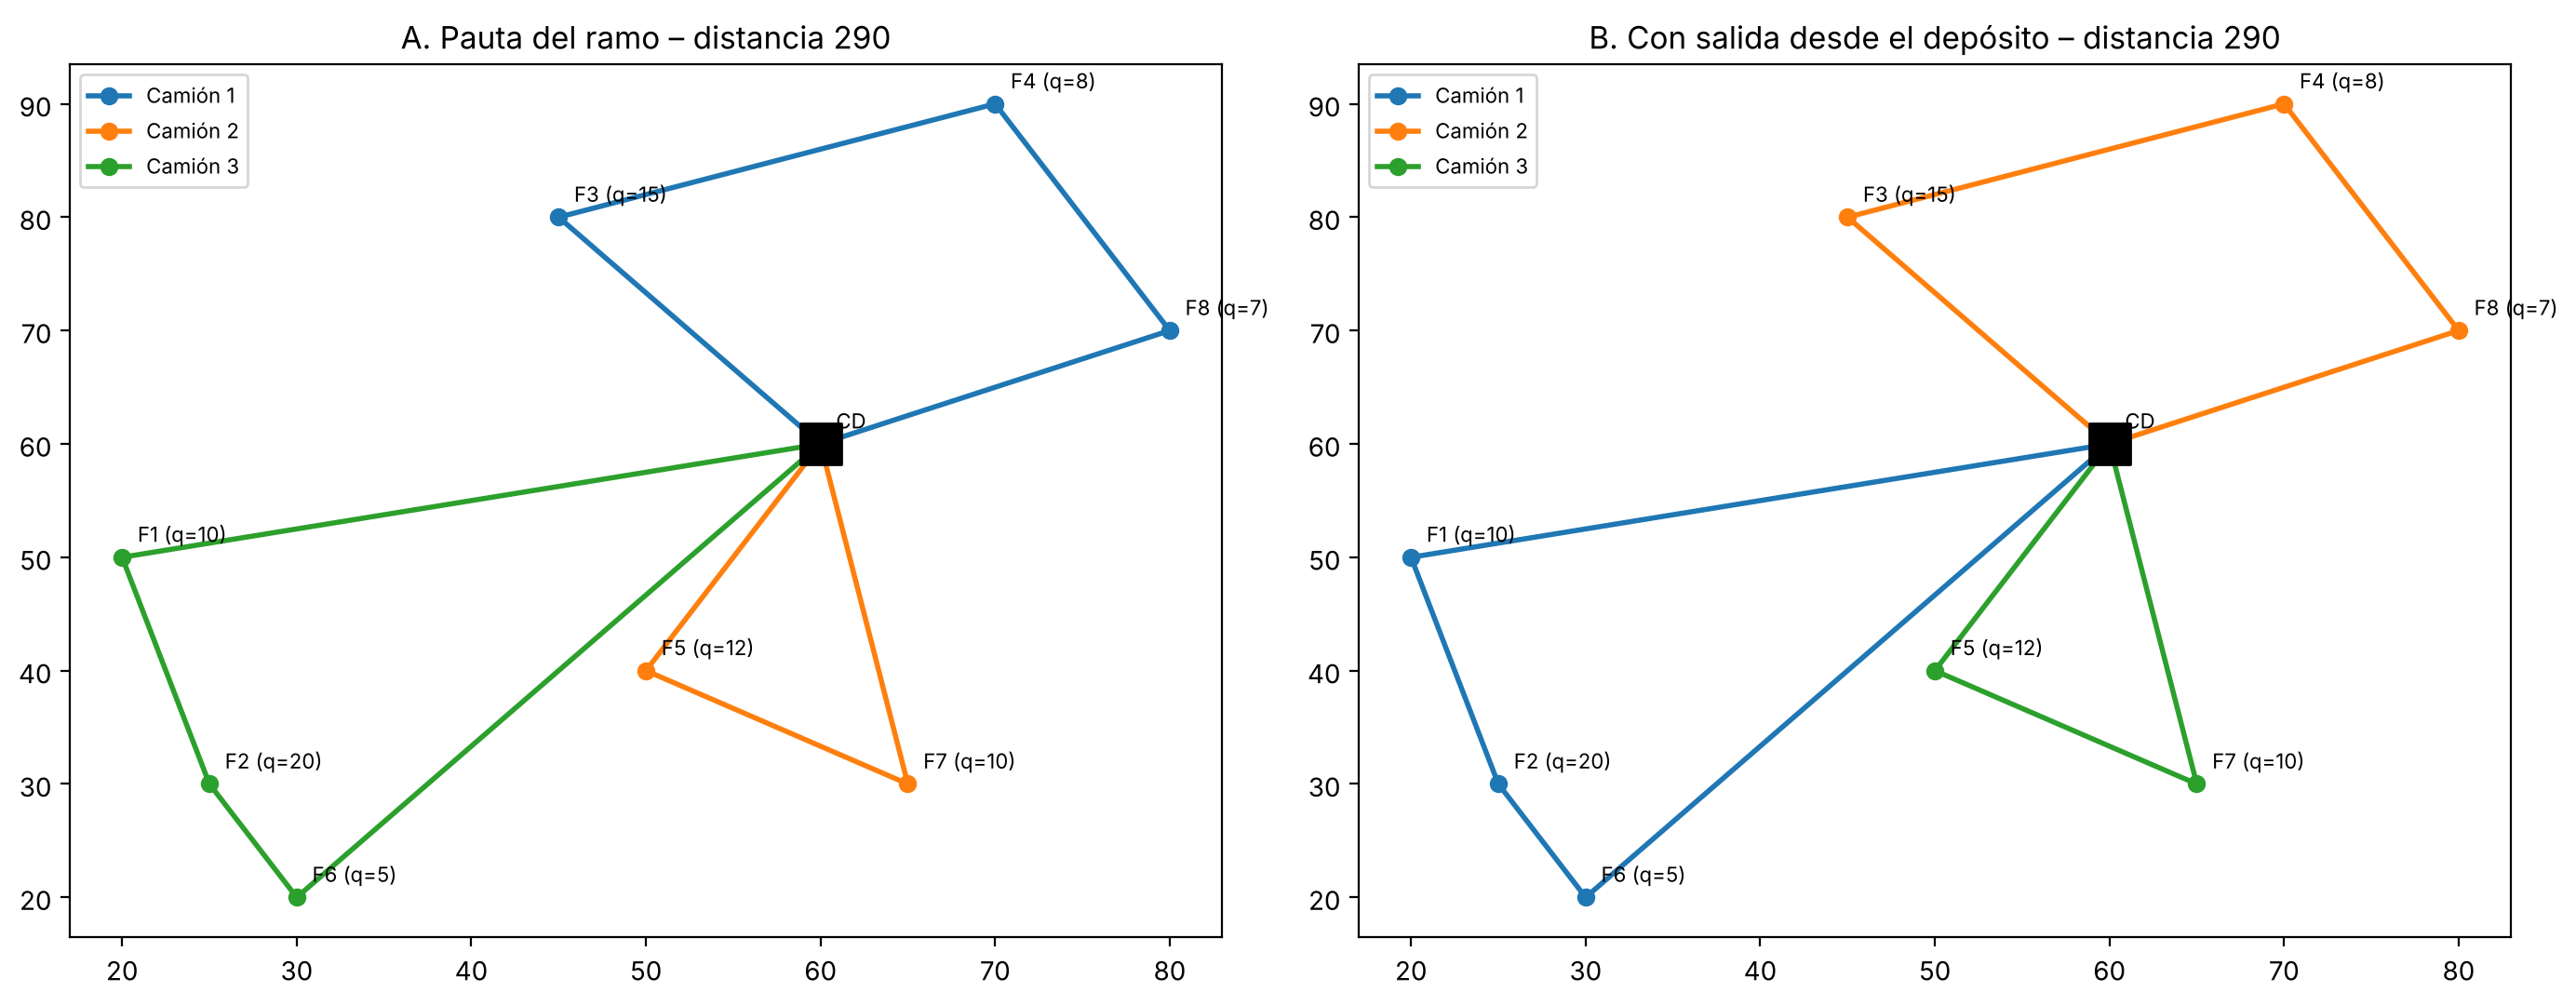

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
plot_routes(coords, solA["routes"], q, f"A. Pauta del ramo – distancia {solA['obj']:.0f}", axes[0])
plot_routes(coords, solB["routes"], q, f"B. Con salida desde el depósito – distancia {solB['obj']:.0f}", axes[1])
plt.tight_layout(); plt.savefig(FIG / "rutas_ejercicio.png", dpi=120); plt.show()

## Parte C – Caso Coquimbo – La Serena

Supuestos (editables en la celda):
- Centro de distribución en el sector industrial de Alto Peñuelas.
- 10 farmacias en distintos sectores de la conurbación (coordenadas aproximadas del sector, no direcciones reales).
- Distancia por carretera ≈ 1,3 × distancia en línea recta (haversine); velocidad media urbana 30 km/h; 10 min de
  descarga por farmacia. Ventanas en minutos desde las 08:00.
- 3 camiones de 60 cajas.

In [8]:
cd = pd.DataFrame([
    ("CD Alto Peñuelas",        -29.9685, -71.2770,  0,   0, 600),
    ("La Serena Centro",        -29.9045, -71.2489, 14,  60, 180),
    ("Las Compañías",           -29.8738, -71.2372, 10,   0, 120),
    ("La Florida (La Serena)",  -29.9250, -71.2215,  8,  90, 240),
    ("Av. del Mar",             -29.9200, -71.2760,  6, 120, 300),
    ("San Joaquín",             -29.9330, -71.2470,  9,  30, 150),
    ("Peñuelas",                -29.9470, -71.2850,  7,  60, 240),
    ("Coquimbo Centro",         -29.9533, -71.3436, 12,   0, 120),
    ("Sindempart",              -29.9790, -71.3250,  8, 120, 300),
    ("Tierras Blancas",         -29.9830, -71.3000, 11,  30, 180),
    ("La Herradura",            -29.9810, -71.3600,  5, 150, 360),
], columns=["nombre", "lat", "lon", "demanda", "abre", "cierra"])

ROAD_FACTOR, SPEED_KMH, SERVICE_MIN = 1.3, 30, 10
def haversine(a, b):
    R = 6371.0
    la1, lo1, la2, lo2 = map(math.radians, (a[0], a[1], b[0], b[1]))
    h = math.sin((la2 - la1) / 2) ** 2 + math.cos(la1) * math.cos(la2) * math.sin((lo2 - lo1) / 2) ** 2
    return 2 * R * math.asin(math.sqrt(h))

pts = list(zip(cd.lat, cd.lon)); n = len(pts)
km = {(i, j): ROAD_FACTOR * haversine(pts[i], pts[j]) for i in range(n) for j in range(n) if i != j}
mins = {(i, j): km[i, j] / SPEED_KMH * 60 + (SERVICE_MIN if i != 0 else 0) for (i, j) in km}
cd

,nombre,lat,lon,demanda,abre,cierra
0,CD Alto Peñuelas,-29.9685,-71.2770,0,0,600
1,La Serena Centro,-29.9045,-71.2489,14,60,180
2,Las Compañías,-29.8738,-71.2372,10,0,120
3,La Florida (La Serena),-29.9250,-71.2215,8,90,240
4,Av. del Mar,-29.9200,-71.2760,6,120,300
5,San Joaquín,-29.9330,-71.2470,9,30,150
6,Peñuelas,-29.9470,-71.2850,7,60,240
7,Coquimbo Centro,-29.9533,-71.3436,12,0,120
8,Sindempart,-29.9790,-71.3250,8,120,300
9,Tierras Blancas,-29.9830,-71.3000,11,30,180


In [9]:
solC = solve_vrptw(pts, list(cd.demanda), list(zip(cd.abre, cd.cierra)), Q=60, n_veh=3,
                   dist=km, ttime=mins, depot_times=True)
print(f"Estado: {solC['status']} | Distancia total: {solC['obj']:.1f} km | {solC['secs']:.1f} s")
rows = []
for k, r in solC["routes"].items():
    for pos, i in enumerate(r[1:-1], 1):
        t = solC["arrival"][k, i]
        rows.append({"Camión": k, "Orden": pos, "Farmacia": cd.nombre[i],
                     "Llegada": f"{8 + int(t // 60):02d}:{int(t % 60):02d}",
                     "Ventana": f"{8 + cd.abre[i] // 60:02d}:{cd.abre[i] % 60:02d}–{8 + cd.cierra[i] // 60:02d}:{cd.cierra[i] % 60:02d}",
                     "Cajas": cd.demanda[i]})
plan = pd.DataFrame(rows)
plan.to_csv("../data/plan_rutas_coquimbo.csv", index=False)
plan

Estado: Optimal | Distancia total: 64.3 km | 1.2 s


,Camión,Orden,Farmacia,Llegada,Ventana,Cajas
0,1,1,San Joaquín,08:30,08:30–10:30,9
1,1,2,La Florida (La Serena),09:30,09:30–12:00,8
2,1,3,Las Compañías,09:55,08:00–10:00,10
3,1,4,La Serena Centro,11:00,09:00–11:00,14
4,1,5,Av. del Mar,11:41,10:00–13:00,6
5,1,6,Peñuelas,12:00,09:00–12:00,7
6,2,1,Tierras Blancas,08:30,08:30–11:00,11
7,3,1,Coquimbo Centro,10:00,08:00–10:00,12
8,3,2,La Herradura,10:30,10:30–14:00,5
9,3,3,Sindempart,13:00,10:00–13:00,8


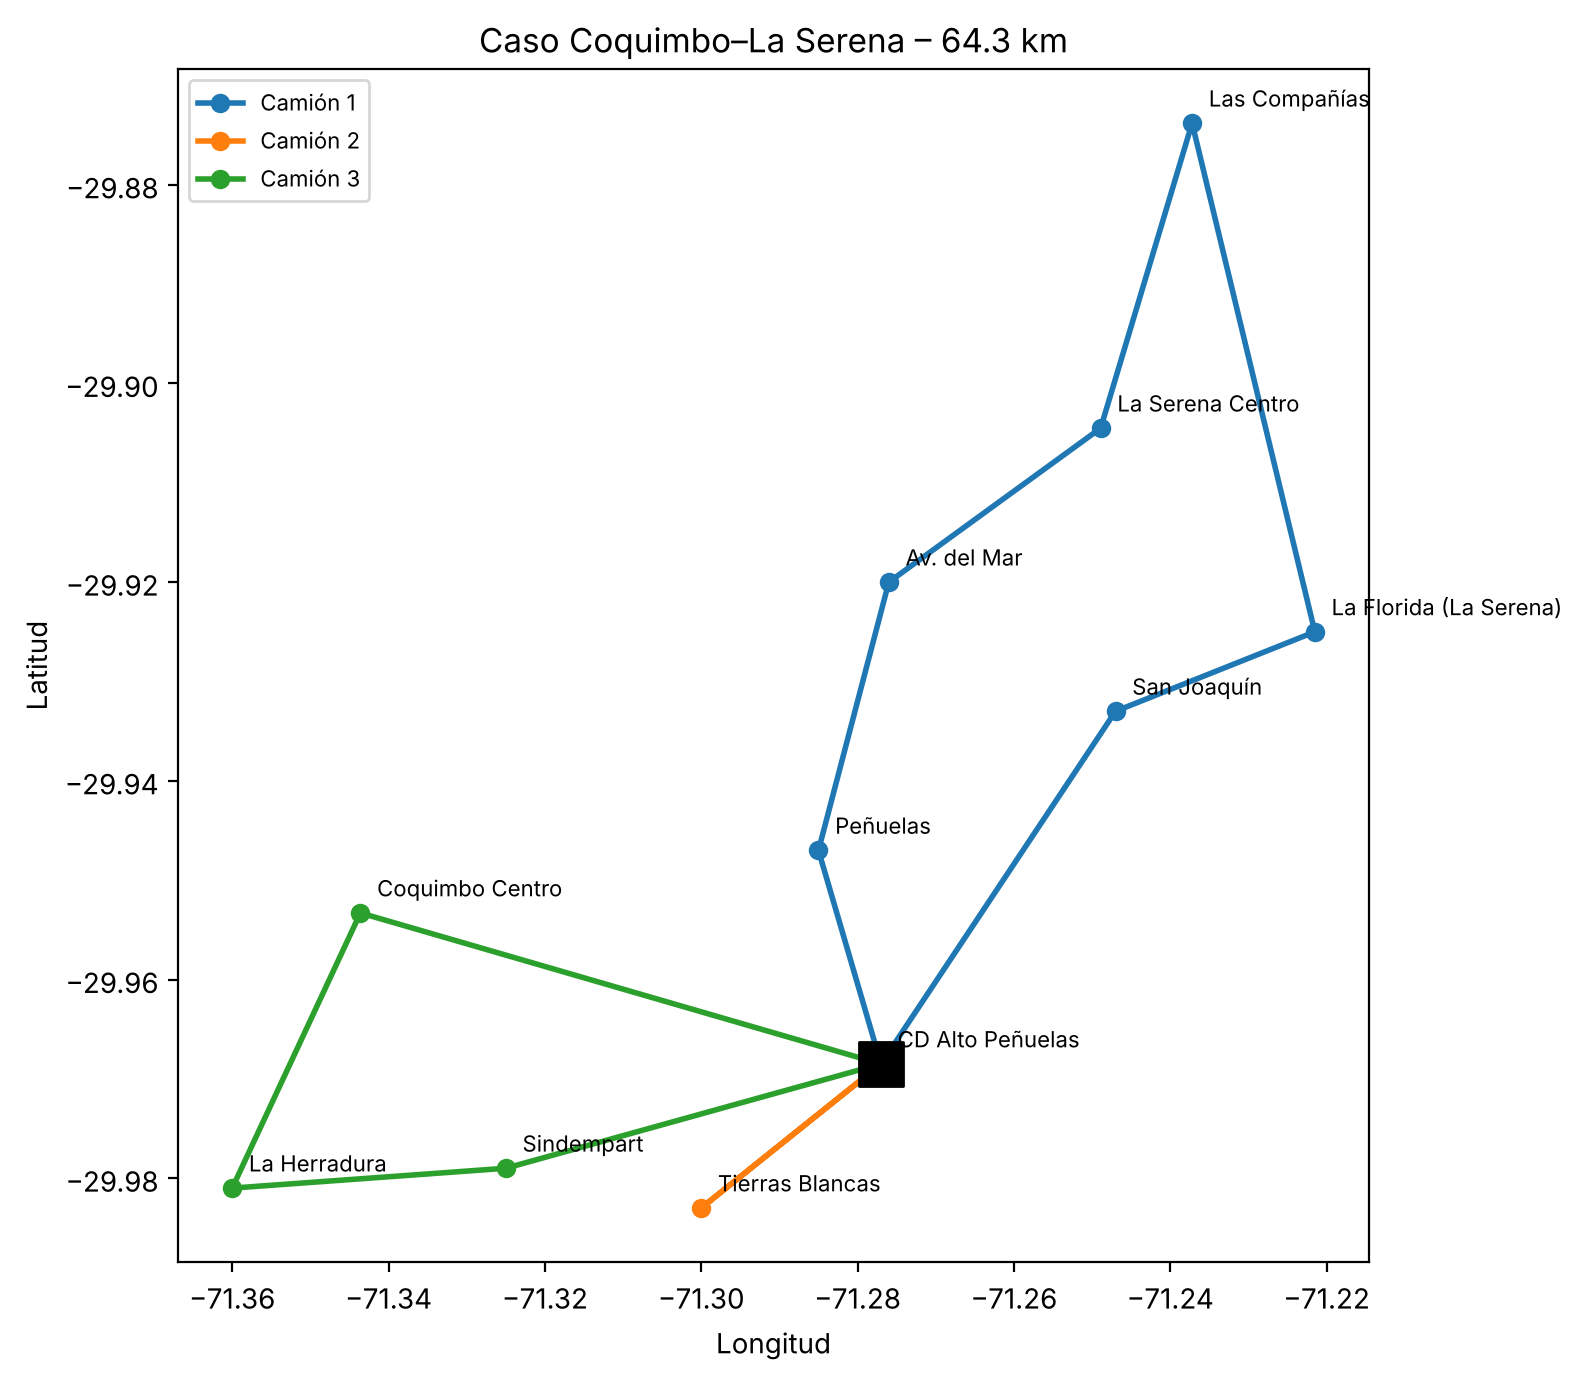

In [10]:
fig, ax = plt.subplots(figsize=(8, 7))
plot_routes([(lo, la) for la, lo in pts], solC["routes"], list(cd.demanda),
            f"Caso Coquimbo–La Serena – {solC['obj']:.1f} km", ax, labels=list(cd.nombre))
ax.set_xlabel("Longitud"); ax.set_ylabel("Latitud")
plt.tight_layout(); plt.savefig(FIG / "rutas_coquimbo.png", dpi=120); plt.show()

In [11]:
import folium
mp = folium.Map(location=[-29.94, -71.29], zoom_start=12, tiles="cartodbpositron")
palette = ["#1f77b4", "#ff7f0e", "#2ca02c"]
for k, r in solC["routes"].items():
    folium.PolyLine([pts[i] for i in r], color=palette[k - 1], weight=5, opacity=0.8,
                    tooltip=f"Camión {k}").add_to(mp)
for i, row in cd.iterrows():
    folium.Marker([row.lat, row.lon], tooltip=f"{row.nombre} ({row.demanda} cajas)",
                  icon=folium.Icon(color="black" if i == 0 else "lightgray",
                                   icon="home" if i == 0 else "plus-sign")).add_to(mp)
mp.save("../figures/mapa_rutas.html")
mp

/usr/local/lib/python3.13/site-packages/folium/raster_layers.py:129: UserWarning: CartoDB tiles now require an API key. Please provide one to continue using the tiles. You can request the key at https://carto.com/basemaps/apikey/.
  tiles = tiles.build_url(fill_subdomain=False, scale_factor="{r}")  # type: ignore


## Sensibilidad: ¿cuántos camiones hacen falta?

In [12]:
sens = []
for veh in [2, 3, 4]:
    s = solve_vrptw(pts, list(cd.demanda), list(zip(cd.abre, cd.cierra)), Q=60, n_veh=veh,
                    dist=km, ttime=mins, depot_times=True)
    sens.append({"Camiones": veh, "Estado": s["status"], "Km totales": round(s["obj"], 1) if s["obj"] else None})
pd.DataFrame(sens)

,Camiones,Estado,Km totales
0,2,Optimal,59.1
1,3,Optimal,64.3
2,4,Optimal,70.5


## Conclusiones
- La implementación en PuLP/CBC reproduce el óptimo de la pauta (**290**) sin licencia de Gurobi.
- La formulación de la pauta permite llegar a la primera farmacia "teletransportándose" desde el depósito. En el
  ejercicio el óptimo es el mismo, pero sin la corrección el modelo podría entregar horarios imposibles.
- Como la pauta obliga a que **todos** los camiones salgan, uno termina haciendo un viaje corto; la sensibilidad
  muestra que con 2 camiones se recorren menos km (59,1 vs 64,3), así que el tercer camión solo conviene si las
  ventanas o la jornada lo exigen.
- El caso local muestra cómo pasar de un ejercicio de clases a una herramienta: basta con cambiar la tabla de
  puntos, demandas y horarios. Con distancias reales de calle (por ejemplo, OSRM o Google Distance Matrix) el
  modelo queda listo para usarse.